# M3 · E1: is pooled training dominated by some generators?

**Decision after M2/M2b.** A small random latent cannot express the LayerNorm adaptation (M2b: d ≤ 1024 is no better than training the head alone; d = 4096 recovers 53% of the gap on seen generators and 37% on FaceShifter). GBLA therefore works directly on the LayerNorm + head parameters (P = 104,450, as in M1): a shared θ_s plus per-generator offsets δ_g with the penalty λ Σ‖δ_g‖²; only θ_s is deployed. The compact-payload claim is dropped.

**E1 question.** Pooled training (M1) minimises the sum of the generators' losses. Near the solutions, each generator's loss is roughly a bowl around its own solution v_g with curvature H_g, and the pooled solution is then the **curvature-weighted** average

θ* ≈ (Σ_g H_g)⁻¹ Σ_g H_g v_g.

Generators with high curvature pull harder. GBLA's argument: this weighting is set by how *sharp* each generator's loss is, not by how useful the generator is for unseen generators, so a few generators can dominate. GBLA replaces H_g by A_g = (H_g + 2λI)⁻¹ H_g, which moves the weights towards equal as λ decreases (random-effects view, τ² = 1/(2λ)).

**What M3 measures**

1. **Per-generator solutions v_g:** M1's recipe trained on one generator at a time, 10 epochs. Each epoch uses all fakes of that generator plus a fresh random quarter of the reals, which is exactly that generator's share of M1's pooled loss (so Σ_g L_g is the pooled loss). By-product: a cross-generator table (train on one, test on all five).
2. **Geometric weights:** the subspace spanned by v_g − θ0 (4 directions, θ0 = CLIP + initial head). Writing M1's pooled solution (epoch 10, same budget) as θ* − θ0 ≈ Σ_g w_g (v_g − θ0) gives weights that describe what pooled training actually did.
3. **Curvature-predicted weights:** the 4 × 4 curvature of each L_g in that subspace, from finite differences of exact gradients (fp32), at θ* and at v_g. Plugged into the formula above, it predicts θ*, hence a second set of weights.
4. **Effective number of generators:** G_eff = (Σw)² / Σw² (Kish); G_eff = G = 4 means equal pull.

**Go / no-go for GBLA:** GO if the two sets of weights agree (same ranking, normalised weights within 0.10), which means the curvature model explains pooled training, **and** G_eff / G ≤ 0.70, which means a real imbalance exists. 5.4 also predicts how GBLA's weights and G_eff move with λ, which gives the λ range for M4.

| Section | What it does | Run time |
|---|---|---|
| 1. Setup | settings, imports | seconds |
| 2. Data | crops into RAM, per-generator sampler | ~3–8 min (disk speed) |
| 3. Model | M1's detector, parameter report | ~1 min |
| 4. Per-generator runs | 4 × 10 epochs (resumable), cross-generator table | ~1.5 h |
| 5. E1 | subspace, curvature (resumable), weights, G_eff, λ prediction, verdict | ~1–1.5 h |
| 6. Send results back | push this notebook | – |

## 1. Setup

### 1.1 Settings

Training settings are M1's. `POOLED_EPOCH = 10` picks the M1 checkpoint with the same budget as the per-generator runs (end of the first learning-rate cycle). Results go to `runs/m3/`.

In [1]:
# 1.1 Settings
import os
from pathlib import Path

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")   # same as M0-M2b
FACES_ROOT = DATA_ROOT / "faces"
INDEX_CSV = DATA_ROOT / "index" / "ffpp_c23.csv"
RUNS_ROOT = DATA_ROOT / "runs"
M3_DIR = RUNS_ROOT / "m3"

# protocol (same as M1)
ALL_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
TRAIN_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]   # FaceShifter = unseen
SHORT = {"original": "real", "Deepfakes": "DF", "Face2Face": "F2F", "FaceSwap": "FS",
         "NeuralTextures": "NT", "FaceShifter": "FSh"}
G = len(TRAIN_GENERATORS)

# M1's LN-tuning recipe
ARCH, PRETRAINED = "ViT-L-14", "openai"
L2_NORM = True
W_UNIFORM, W_ALIGN = 0.5, 0.1
AUGMENT = True
BATCH_SIZE = 128
EPOCHS = 10
CYCLE_EPOCHS = 10
WARMUP_EPOCHS = 1
LR_MAX, LR_MIN = 3e-4, 1e-5
SEED = 0

# the pooled solution (M1) with the same budget
M1_RUN_DIR = RUNS_ROOT / "m1" / f"lnclip_{ARCH}_train-{'-'.join(SHORT[g] for g in TRAIN_GENERATORS)}_seed{SEED}"
POOLED_EPOCH = 10

# E1 curvature measurement
CURV_BATCHES = 12                    # fixed, unaugmented batches per generator
CURV_FAKE = 100
CURV_REAL = CURV_FAKE // G           # real : fake = 1 : G, each generator's share of the pooled loss
CURV_EPS = [1e-2, 3e-2]              # finite-difference steps: the first is used, the second checks it
GO_MAX_WEIGHT_DIFF = 0.10            # go/no-go thresholds (see the introduction)
GO_MAX_GEFF_RATIO = 0.70

# speed only
VAL_FRAMES_PER_VIDEO = 8
CACHE_IN_RAM = True
EVAL_BATCH = 256
GRAD_CHECKPOINTING = False

COMMON_CONFIG = {
    "arch": ARCH, "pretrained": PRETRAINED, "quick_gelu": True, "l2_norm": L2_NORM,
    "w_uniform": W_UNIFORM, "w_align": W_ALIGN, "augment": AUGMENT,
    "batch_size": BATCH_SIZE, "epochs": EPOCHS, "cycle_epochs": CYCLE_EPOCHS,
    "warmup_epochs": WARMUP_EPOCHS, "lr_max": LR_MAX, "lr_min": LR_MIN, "seed": SEED,
    "reals_per_epoch": f"1/{G} of the train reals, redrawn each epoch",
}
assert INDEX_CSV.exists(), f"index not found: {INDEX_CSV} (run M0 first)"
assert (M1_RUN_DIR / f"epoch_{POOLED_EPOCH:02d}.pt").exists(), f"M1 checkpoint not found in {M1_RUN_DIR}"
M3_DIR.mkdir(parents=True, exist_ok=True)
print("M3 results go to:", M3_DIR)

M3 results go to: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m3


### 1.2 Imports and environment

`os.cpu_count()` reports the whole node (256), but the job may only use the CPUs in its affinity mask and cgroup quota; the loader uses that number. Free RAM decides in 2.2 how many crops can be kept in memory.

In [2]:
# 1.2 Imports and environment
import json, math, random, time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Sampler
from torchvision import tv_tensors
from torchvision.io import ImageReadMode, read_image
from torchvision.transforms import v2 as T
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
assert torch.cuda.is_available(), "M3 needs the GPU"
DEVICE = "cuda"


def usable_cpus():
    """CPUs this job may use: the affinity mask and the cgroup CPU quota."""
    n = len(os.sched_getaffinity(0))
    for quota_file, period_file in [("/sys/fs/cgroup/cpu.max", None),
                                    ("/sys/fs/cgroup/cpu/cpu.cfs_quota_us", "/sys/fs/cgroup/cpu/cpu.cfs_period_us")]:
        try:
            if period_file is None:
                quota, period = Path(quota_file).read_text().split()
            else:
                quota, period = Path(quota_file).read_text().strip(), Path(period_file).read_text().strip()
            if quota not in ("max", "-1"):
                n = min(n, max(1, int(quota) // int(period)))
        except (OSError, ValueError):
            pass
    return n


def available_memory_gb():
    """Free RAM for this job: the smaller of MemAvailable and the cgroup limit minus non-cache usage."""
    candidates = []
    try:
        meminfo = dict(line.split(":", 1) for line in Path("/proc/meminfo").read_text().splitlines())
        candidates.append(int(meminfo["MemAvailable"].split()[0]) * 1024)
    except (OSError, KeyError, ValueError):
        pass
    for limit_file, usage_file, stat_file, cache_key in [
            ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory.current", "/sys/fs/cgroup/memory.stat", "file"),
            ("/sys/fs/cgroup/memory/memory.limit_in_bytes", "/sys/fs/cgroup/memory/memory.usage_in_bytes",
             "/sys/fs/cgroup/memory/memory.stat", "cache")]:
        try:
            limit = Path(limit_file).read_text().strip()
            if not limit.isdigit() or int(limit) >= 1 << 60:
                continue
            usage = int(Path(usage_file).read_text().strip())
            stat = dict(line.split() for line in Path(stat_file).read_text().splitlines())
            candidates.append(int(limit) - usage + int(stat.get(cache_key, 0)))
        except (OSError, ValueError):
            pass
    return min(candidates) / 1e9 if candidates else 0.0


CPUS = usable_cpus()
NUM_WORKERS = max(1, min(16, CPUS - 1))     # one CPU stays with the training process
torch.set_num_threads(2)

pd.Series({
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "open_clip": open_clip.__version__,
    "GPU": torch.cuda.get_device_name(0),
    "CPU cores on the node": os.cpu_count(),
    "CPUs usable by this job": CPUS,
    "data loader workers": NUM_WORKERS,
    "free RAM for this job (GB)": round(available_memory_gb(), 1),
}, name="value").to_frame()

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
torch,2.6.0+cu124
torchvision,0.21.0+cu124
open_clip,3.3.0
GPU,NVIDIA A100-SXM4-40GB
CPU cores on the node,256
CPUs usable by this job,16
data loader workers,15
free RAM for this job (GB),1037.3


## 2. Data

### 2.1 Index and subsets

Same splits as M1: train = real + the 4 training generators (115,200 crops); test = real + all 5 generators, FaceShifter unseen. Val keeps 8 evenly spaced frames of each video (5,600 crops instead of 22,400). Val only monitors training, so this changes no trained model; val numbers are therefore not identical to M1's.

In [3]:
# 2.1 Index and subsets
index = pd.read_csv(INDEX_CSV, dtype={"video_id": str, "target_id": str, "source_id": str},
                    keep_default_na=False)
CATEGORIES = ["original"] + ALL_GENERATORS
GEN_CODE = {g: k for k, g in enumerate(CATEGORIES)}


def subset(split, generators):
    keep = (index.split == split) & index.generator.isin(["original", *generators])
    return index[keep].reset_index(drop=True)


train_df = subset("train", TRAIN_GENERATORS)
val_all = subset("val", TRAIN_GENERATORS)
frames_per_video = int(val_all.groupby(["generator", "video_id"]).size().max())
keep_every = max(1, frames_per_video // VAL_FRAMES_PER_VIDEO)
frame_rank = val_all.groupby(["generator", "video_id"]).frame_idx.rank(method="first").astype(int) - 1
val_df = val_all[frame_rank % keep_every == 0].reset_index(drop=True)
test_df = subset("test", ALL_GENERATORS)

display(pd.DataFrame({name: df.groupby("generator").size().reindex(CATEGORIES)
                      for name, df in [("train", train_df), ("val (subsampled)", val_df), ("test", test_df)]}
                     ).fillna(0).astype(int))

,train,val (subsampled),test
generator,,,
original,23040,1120,4480
Deepfakes,23040,1120,4480
Face2Face,23040,1120,4480
FaceSwap,23040,1120,4480
NeuralTextures,23040,1120,4480
FaceShifter,0,0,4480


### 2.2 Decoded crops in RAM

Reading 115,200 small PNG files per epoch from the network file system was the likely M1 bottleneck. Here every crop is read once per session into one uint8 array (224 × 224 × 3 bytes per crop: train 17.3 GB, val 0.8 GB, test 4.0 GB), in the order train → val → test, as long as it fits in 60% of free RAM. Sets that don't fit are read from disk as in M1. Nothing is written to disk. The printed read speed also tells us how fast the file system is.

In [4]:
# 2.2 Decoded crops in RAM
def load_images(df, desc):
    """Decodes every crop of an index slice into one uint8 array (N, H, W, 3), using threads."""
    paths = [FACES_ROOT / p for p in df.path]
    first = np.asarray(Image.open(paths[0]).convert("RGB"))
    out = np.empty((len(paths), *first.shape), dtype=np.uint8)

    def work(k):
        out[k] = np.asarray(Image.open(paths[k]).convert("RGB"))

    with ThreadPoolExecutor(max_workers=min(32, 4 * CPUS)) as pool:
        list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc=desc, mininterval=5))
    return out


images = {}
budget = 0.6 * available_memory_gb()
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    need = len(df) * 224 * 224 * 3 / 1e9
    if CACHE_IN_RAM and need <= budget:
        t = time.time()
        images[name] = load_images(df, f"{name} crops -> RAM")
        budget -= need
        sec = time.time() - t
        print(f"{name}: {len(df):,} crops, {need:.1f} GB in RAM, {sec / 60:.1f} min ({len(df) / sec:.0f} crops/s from disk)")
    else:
        images[name] = None
        print(f"{name}: read from disk during training (needs {need:.1f} GB, RAM budget left {budget:.1f} GB)")

train crops -> RAM: 100%|██████████| 115200/115200 [00:49<00:00, 2339.46it/s]


train: 115,200 crops, 17.3 GB in RAM, 0.9 min (2206 crops/s from disk)


val crops -> RAM: 100%|██████████| 5600/5600 [00:02<00:00, 2245.46it/s]


val: 5,600 crops, 0.8 GB in RAM, 0.0 min (2152 crops/s from disk)


test crops -> RAM: 100%|██████████| 26880/26880 [00:11<00:00, 2354.42it/s]

test: 26,880 crops, 4.0 GB in RAM, 0.2 min (2248 crops/s from disk)


### 2.3 Datasets and per-generator loader

Same transforms and augmentations as M1. The sampler builds each epoch from **all training fakes of one generator plus a fresh random 1/G of the training reals** (23,040 + 5,760 crops, 225 steps). Real : fake = 1 : G is exactly the share each generator has in M1's pooled loss, so the four per-generator losses add up to the pooled loss. The order depends only on (seed, generator, epoch), so resumed runs see the same data. `train_sampler.configure(g)` switches the generator.

In [5]:
# 2.3 Datasets and per-generator loader
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)


def make_transform(train):
    steps = []
    if train and AUGMENT:
        steps += [
            T.RandomHorizontalFlip(0.5),
            T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
            T.RandomApply([T.GaussianBlur(kernel_size=7, sigma=(0.1, 2.0))], p=0.1),
            T.ColorJitter(brightness=0.1, contrast=0.1),
            T.JPEG(quality=(40, 100)),
        ]
    steps += [T.ToDtype(torch.float32, scale=True), T.Normalize(CLIP_MEAN, CLIP_STD)]
    return T.Compose(steps)


class FaceDataset(Dataset):
    """Returns (image, label, generator code) for every row of an index slice."""

    def __init__(self, df, train, images=None):
        self.paths = [str(FACES_ROOT / p) for p in df.path]
        self.images = images
        self.labels = torch.tensor(df.label.values, dtype=torch.long)
        self.gens = torch.tensor(df.generator.map(GEN_CODE).values, dtype=torch.long)
        self.transform = make_transform(train)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        if self.images is not None:
            image = torch.from_numpy(np.array(self.images[i])).permute(2, 0, 1)
        else:
            image = read_image(self.paths[i], mode=ImageReadMode.RGB)
        return self.transform(tv_tensors.Image(image)).as_subclass(torch.Tensor), self.labels[i], self.gens[i]


class GeneratorEpochSampler(Sampler):
    """One epoch = all training fakes of one generator + a fresh random 1/G of the reals."""

    def __init__(self, df, seed):
        self.gen_of_row = df.generator.values
        self.real_idx = np.flatnonzero(self.gen_of_row == "original")
        self.seed, self.epoch, self.generator = seed, 0, None

    def configure(self, generator):
        self.generator = generator
        self.fake_idx = np.flatnonzero(self.gen_of_row == generator)
        self.n_real = len(self.fake_idx) // G

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        rng = np.random.default_rng([self.seed, ALL_GENERATORS.index(self.generator), self.epoch])
        reals = rng.choice(self.real_idx, self.n_real, replace=False)
        return iter(rng.permutation(np.concatenate([self.fake_idx, reals])).tolist())

    def __len__(self):
        return len(self.fake_idx) + self.n_real


train_ds = FaceDataset(train_df, train=True, images=images["train"])
train_sampler = GeneratorEpochSampler(train_df, SEED)
train_sampler.configure(TRAIN_GENERATORS[0])
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=train_sampler, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True, prefetch_factor=4)
print(f"per generator and epoch: {len(train_sampler.fake_idx):,} fakes + {train_sampler.n_real:,} reals "
      f"= {len(train_loader)} steps;  loader workers: {NUM_WORKERS}")

per generator and epoch: 23,040 fakes + 5,760 reals = 225 steps;  loader workers: 15


### 2.4 Data-loading speed

Measured properly this time: the batches the workers prepared in advance are taken out first, then 30 batches are timed. Also measured: the CPU time to prepare one augmented crop in a single process. If loading is slower than the GPU (M1: 253 img/s), the table says so; send me the output and I'll move the augmentations to the GPU.

In [6]:
# 2.4 Data-loading speed
def loader_rate(loader, n_batches=30):
    """Steady-state images/s after the pre-fetched batches are used up."""
    it = iter(loader)
    for _ in range(NUM_WORKERS * 4 + 2):
        next(it)
    t = time.time()
    for _ in range(n_batches):
        next(it)
    rate = n_batches * loader.batch_size / (time.time() - t)
    del it
    return rate


t = time.time()
for i in range(200):
    train_ds[i]
ms_per_crop = (time.time() - t) / 200 * 1000
load_speed = loader_rate(train_loader)
GPU_SPEED_M1 = 253
speed = min(load_speed, GPU_SPEED_M1)
pd.Series({
    "CPU time per augmented crop, one process (ms)": round(ms_per_crop, 1),
    "data loading speed (img/s)": round(load_speed),
    "GPU training speed in M1 (img/s)": GPU_SPEED_M1,
    "bottleneck": "GPU" if load_speed >= GPU_SPEED_M1 else "data loading",
    "estimated minutes per epoch (training part)": round(len(train_loader) * BATCH_SIZE / speed / 60, 1),
    f"estimated hours per generator ({EPOCHS} epochs)": round(EPOCHS * len(train_loader) * BATCH_SIZE / speed / 3600, 1),
}, name="value").to_frame()

,value
"CPU time per augmented crop, one process (ms)",12.8
data loading speed (img/s),2068
GPU training speed in M1 (img/s),253
bottleneck,GPU
estimated minutes per epoch (training part),1.9
estimated hours per generator (10 epochs),0.3


## 3. Model

### 3.1 Detector (as in M1)

CLIP ViT-L/14 (QuickGELU, 1024-d CLS token, L2-normalised), 50 LayerNorms + linear head trainable, same initial head as M1 (`SEED`). θ0 = these starting values. All E1 computations use θ as one flat vector of the P = 104,450 trainable numbers in a fixed order (`get_flat` / `set_flat`).

In [7]:
# 3.1 Detector (as in M1)
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None                      # keep the 1024-d CLS token
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        """Returns (logits, L2-normalized features)."""
        feats = self.encoder(x).float()
        f = F.normalize(feats, dim=-1)
        return self.head(f if L2_NORM else feats), f


torch.manual_seed(SEED)
model = Detector().to(DEVICE)
model.requires_grad_(False)
for m in model.encoder.modules():
    if isinstance(m, nn.LayerNorm):
        m.requires_grad_(True)
model.head.requires_grad_(True)
model.encoder.set_grad_checkpointing(GRAD_CHECKPOINTING)

PARAMS = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
PARAM_NAMES = [n for n, _ in PARAMS]
P = sum(p.numel() for _, p in PARAMS)


def get_flat():
    return torch.cat([p.detach().reshape(-1) for _, p in PARAMS]).float()


@torch.no_grad()
def set_flat(theta):
    offset = 0
    for _, p in PARAMS:
        n = p.numel()
        p.copy_(theta[offset:offset + n].view_as(p))
        offset += n


def flat_grad():
    return torch.cat([p.grad.reshape(-1) for _, p in PARAMS]).float()


def flat_from_state(state):
    return torch.cat([state[n].reshape(-1).float() for n in PARAM_NAMES]).to(DEVICE)


def trainable_state():
    return {n: p.detach().cpu().clone() for n, p in PARAMS}


THETA0 = get_flat().clone()
print(f"trainable numbers P = {P:,}")
if ARCH == "ViT-L-14":
    assert P == 104_450

trainable numbers P = 104,450


### 3.2 Parameter report

Same model as M1: expected trainable 104,450 = LayerNorm 102,400 + head 2,050 (0.0345%). E1 adds no parameters; during the per-generator runs exactly one copy of these numbers is trained at a time.

In [8]:
# 3.2 Parameter report
def module_group(name):
    parts = name.split(".")
    if parts[0] == "head":
        return "linear head"
    if parts[-2].startswith("ln_"):
        return "LayerNorm"
    if "attn" in parts:
        return "attention"
    if "mlp" in parts:
        return "MLP"
    if "conv1" in parts:
        return "patch embedding"
    return "class + positional embedding"


rows = defaultdict(lambda: {"parameters": 0, "trainable": 0, "frozen": 0})
for name, p in model.named_parameters():
    g = rows[module_group(name)]
    g["parameters"] += p.numel()
    g["trainable" if p.requires_grad else "frozen"] += p.numel()
per_module = pd.DataFrame(rows).T.sort_values("parameters", ascending=False)
per_module.loc["TOTAL"] = per_module.sum()
total = int(per_module.loc["TOTAL", "parameters"])
display(per_module.style.format("{:,}"))
display(pd.Series({"total": total, "trainable": P, "frozen": total - P,
                   "trainable %": round(100 * P / total, 4)}, name="value").to_frame())

,parameters,trainable,frozen
MLP,"201,449,472",0,"201,449,472"
attention,"100,761,600",0,"100,761,600"
patch embedding,"602,112",0,"602,112"
class + positional embedding,"264,192",0,"264,192"
LayerNorm,"102,400","102,400",0
linear head,"2,050","2,050",0
TOTAL,"303,181,826","104,450","303,077,376"


,value
total,3.031818e+08
trainable,1.044500e+05
frozen,3.030774e+08
trainable %,3.450000e-02


## 4. Per-generator solutions

### 4.1 Helpers

M1's loss (cross-entropy + 0.5 · uniformity + 0.1 · alignment), learning-rate schedule, AUC metrics and atomic checkpoints. `metrics_table` marks as "seen" the generators a model was trained on.

In [9]:
# 4.1 Helpers
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def compute_loss(logits, f, y):
    """Returns (total loss, dict of loss parts, per-sample cross-entropy); f = L2-normalized features."""
    ce_each = F.cross_entropy(logits, y, reduction="none")
    ce = ce_each.mean()
    n = len(y)
    i, j = torch.triu_indices(n, n, offset=1, device=f.device)
    d2 = (2 - 2 * (f @ f.T)[i, j]).clamp(min=0)
    same = y[i] == y[j]
    align = d2[same].mean() if same.any() else d2.new_zeros(())
    uniform = torch.exp(-2 * d2).mean().clamp(min=1e-6).log()
    loss = ce + W_ALIGN * align + W_UNIFORM * uniform
    parts = {"loss": loss.item(), "ce": ce.item(), "align": align.item(), "uniform": uniform.item()}
    return loss, parts, ce_each.detach()


def lr_at(step, steps_per_epoch):
    cycle = CYCLE_EPOCHS * steps_per_epoch
    warm = WARMUP_EPOCHS * steps_per_epoch
    pos = step % cycle
    if pos < warm:
        return LR_MIN + (LR_MAX - LR_MIN) * pos / warm
    frac = (pos - warm) / max(cycle - warm, 1)
    return LR_MIN + 0.5 * (LR_MAX - LR_MIN) * (1 + math.cos(math.pi * frac))


def make_optimizer():
    return torch.optim.AdamW([p for _, p in PARAMS], lr=LR_MIN, betas=(0.9, 0.999), weight_decay=0.0)


def train_step(optimizer, x, y, lr):
    for group in optimizer.param_groups:
        group["lr"] = lr
    with torch.autocast("cuda", dtype=torch.bfloat16):
        logits, f = model(x)
    loss, parts, ce_each = compute_loss(logits.float(), f.float(), y)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    return parts, ce_each


def to_model_input(uint8_batch):
    """uint8 (N, H, W, 3) array or tensor -> normalised float tensor on the GPU."""
    x = torch.as_tensor(uint8_batch).to(DEVICE, non_blocking=True)
    return (x.permute(0, 3, 1, 2).float() / 255 - MEAN_GPU) / STD_GPU


@torch.no_grad()
def predict(df, images=None, desc="predict"):
    """Fake probability for every crop of an index slice, with the current parameters."""
    model.eval()
    probs = []
    if images is not None:
        for s in tqdm(range(0, len(df), EVAL_BATCH), desc=desc, leave=False):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(to_model_input(images[s:s + EVAL_BATCH]))
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    else:
        loader = DataLoader(FaceDataset(df, train=False), batch_size=EVAL_BATCH, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=True)
        for x, _, _ in tqdm(loader, desc=desc, leave=False):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(x.to(DEVICE, non_blocking=True))
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    model.train()
    out = df[["split", "label", "generator", "video_id", "frame_idx", "path"]].copy()
    out["prob"] = torch.cat(probs).numpy()
    return out


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos = labels.sum()
    n_neg = len(labels) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def metrics_table(pred, train_gens):
    """AUC per test set: the training generators together, then each generator alone (vs. the same reals)."""
    groups = {"seen combined (" + "+".join(SHORT[g] for g in train_gens) + ")": train_gens}
    groups.update({g: [g] for g in ALL_GENERATORS})
    rows = []
    for name, gens in groups.items():
        sub = pred[pred.generator.isin(["original", *gens])]
        if (sub.label == 1).sum() == 0:
            continue
        vid = sub.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
        rows.append({
            "test set": name,
            "status": "seen" if set(gens) <= set(train_gens) else "UNSEEN",
            "frame AUC": 100 * auc(sub.label, sub.prob),
            "video AUC": 100 * auc(vid.label, vid.prob),
            "video acc @0.5": 100 * float(((vid.prob > 0.5) == vid.label).mean()),
            "real / fake videos": f"{(vid.label == 0).sum()} / {(vid.label == 1).sum()}",
        })
    return pd.DataFrame(rows).round(2)


def save_atomic(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def check_config(run_dir, config):
    path = run_dir / "config.json"
    if path.exists():
        assert json.loads(path.read_text()) == json.loads(json.dumps(config)), \
            f"{run_dir} holds a run with different settings: restore them or delete the folder"
    else:
        path.write_text(json.dumps(config, indent=1))

### 4.2 Train one model per generator (resumable)

For each training generator: start from θ0, 10 epochs of M1's recipe on that generator's fakes + 1/G of the reals, FF++ val AUC on real + that generator after every epoch, then the full test set (all 5 generators). Run folders: `runs/m3/lnclip_ViT-L-14_train-<DF|F2F|FS|NT>_seed0/` with `epoch_XX.pt`, `last.pt`, `results.json`, `test_predictions.csv`.

**Resuming:** run 1.1 → 4.1 (2.4 optional) and this cell; finished generators are skipped, an interrupted one continues after its last finished epoch.

In [10]:
# 4.2 Train one model per generator (resumable)
def run_dir_for(g):
    return M3_DIR / f"lnclip_{ARCH}_train-{SHORT[g]}_seed{SEED}"


def train_single(g):
    run_dir = run_dir_for(g)
    run_dir.mkdir(parents=True, exist_ok=True)
    check_config(run_dir, {**COMMON_CONFIG, "train_generator": g})
    set_flat(THETA0)
    optimizer = make_optimizer()
    history, start_epoch = [], 0
    if (run_dir / "last.pt").exists():
        ckpt = load(run_dir / "last.pt")
        set_flat(flat_from_state(ckpt["trainable"]))
        optimizer.load_state_dict(ckpt["optimizer"])
        history, start_epoch = ckpt["history"], ckpt["epoch"]
    print(f"\n===== train on {SHORT[g]}: {start_epoch}/{EPOCHS} epochs done =====")

    train_sampler.configure(g)
    val_keep = val_df.generator.isin(["original", g]).values
    val_g = val_df[val_keep].reset_index(drop=True)
    val_images = images["val"][val_keep] if images["val"] is not None else None
    steps_per_epoch = len(train_loader)
    for epoch in range(start_epoch, EPOCHS):
        train_sampler.set_epoch(epoch)
        model.train()
        sums, n_steps, t0 = defaultdict(float), 0, time.time()
        ce_sum = torch.zeros(len(CATEGORIES), device=DEVICE)
        ce_cnt = torch.zeros(len(CATEGORIES), device=DEVICE)
        for i, (x, y, gen) in enumerate(tqdm(train_loader, desc=f"{SHORT[g]} epoch {epoch + 1}/{EPOCHS}", leave=False)):
            lr = lr_at(epoch * steps_per_epoch + i, steps_per_epoch)
            x, y, gen = (t.to(DEVICE, non_blocking=True) for t in (x, y, gen))
            parts, ce_each = train_step(optimizer, x, y, lr)
            for k, v in parts.items():
                sums[k] += v
            ce_sum += torch.bincount(gen, weights=ce_each, minlength=len(CATEGORIES))
            ce_cnt += torch.bincount(gen, minlength=len(CATEGORIES))
            n_steps += 1

        val_table = metrics_table(predict(val_g, val_images, desc="val"), [g])
        row = {"epoch": epoch + 1, "lr (end)": float(lr)}
        row.update({k: v / n_steps for k, v in sums.items()})
        row.update({f"CE {SHORT[c]}": float(ce_sum[k] / ce_cnt[k]) for k, c in enumerate(CATEGORIES) if ce_cnt[k] > 0})
        row.update({"val video AUC": float(val_table["video AUC"].iloc[0]), "minutes": (time.time() - t0) / 60})
        history.append(row)
        save_atomic(trainable_state(), run_dir / f"epoch_{epoch + 1:02d}.pt")
        save_atomic({"epoch": epoch + 1, "trainable": trainable_state(), "optimizer": optimizer.state_dict(),
                     "history": history}, run_dir / "last.pt")
        print(" | ".join(f"{k} {v:.4g}" if isinstance(v, float) else f"{k} {v}" for k, v in row.items()))

    if not (run_dir / "results.json").exists():
        pred = predict(test_df, images["test"], desc="test")
        pred.to_csv(run_dir / "test_predictions.csv", index=False)
        table = metrics_table(pred, [g])
        display(table)
        (run_dir / "results.json").write_text(json.dumps(
            {"train_generator": g, "test": table.to_dict(orient="records"), "history": history}, indent=1))
    del optimizer
    torch.cuda.empty_cache()


for g in TRAIN_GENERATORS:
    train_single(g)
print("all per-generator runs finished")


===== train on DF: 10/10 epochs done =====

===== train on F2F: 10/10 epochs done =====

===== train on FS: 10/10 epochs done =====

===== train on NT: 10/10 epochs done =====
all per-generator runs finished


### 4.3 Cross-generator table

Video AUC of each single-generator model on every test generator (diagonal = seen), next to the pooled model (M1, epoch 10). This is the plain-language view of the question: which training generators transfer to which others, and in particular to FaceShifter. Saved to `runs/m3/cross_generator.csv`.

In [11]:
# 4.3 Cross-generator table
theta_star = flat_from_state(load(M1_RUN_DIR / f"epoch_{POOLED_EPOCH:02d}.pt"))
pooled_path = M3_DIR / "pooled_test.json"
if pooled_path.exists():
    pooled_test = json.loads(pooled_path.read_text())
else:
    set_flat(theta_star)
    pooled_test = metrics_table(predict(test_df, images["test"], desc="pooled"), TRAIN_GENERATORS).to_dict(orient="records")
    pooled_path.write_text(json.dumps(pooled_test, indent=1))

cross = {}
for g in TRAIN_GENERATORS:
    t = pd.DataFrame(json.loads((run_dir_for(g) / "results.json").read_text())["test"]).set_index("test set")
    cross[f"train on {SHORT[g]}"] = {SHORT[h]: t.loc[h, "video AUC"] for h in ALL_GENERATORS}
t = pd.DataFrame(pooled_test).set_index("test set")
cross[f"pooled (M1, epoch {POOLED_EPOCH})"] = {SHORT[h]: t.loc[h, "video AUC"] for h in ALL_GENERATORS}
cross = pd.DataFrame(cross).T
cross.columns = [c if c != "FSh" else "FSh (unseen)" for c in cross.columns]
cross.to_csv(M3_DIR / "cross_generator.csv")
print("video AUC (%), rows = training data, columns = test generator")
display(cross.style.format("{:.2f}").background_gradient(cmap="RdYlGn", vmin=50, vmax=100, axis=None))

video AUC (%), rows = training data, columns = test generator


,DF,F2F,FS,NT,FSh (unseen)
train on DF,99.91,79.64,96.14,55.25,81.80
train on F2F,98.67,98.93,99.20,64.88,83.80
train on FS,99.03,86.07,99.82,51.07,89.56
train on NT,87.68,69.15,80.62,72.15,80.65
"pooled (M1, epoch 10)",99.22,98.09,99.20,93.88,88.19


## 5. E1

### 5.1 Solutions and the subspace they span

U = orthonormal basis of the 4 directions v_g − θ0 (QR). Every solution gets 4 coordinates in this basis: c_g for the per-generator solutions, c* for the pooled one.

- **Explained share:** how much of θ* − θ0 lies in the span (1 = fully). If it is small, pooled training went mostly in directions none of the single-generator runs took, and the 4 weights describe only part of it.
- **Geometric weights:** the unique w with Σ_g w_g c_g = c*, i.e. θ* − θ0 ≈ Σ_g w_g (v_g − θ0). They do not have to sum to 1; 5.3 compares them after normalising to sum 1.

In [12]:
# 5.1 Solutions and the subspace they span
V = torch.stack([flat_from_state(load(run_dir_for(g) / f"epoch_{EPOCHS:02d}.pt")) for g in TRAIN_GENERATORS], 1)
D = (V - THETA0[:, None]).double()                 # P x G
d_star = (theta_star - THETA0).double()
U, R = torch.linalg.qr(D)                           # U: P x G, orthonormal
C = (U.T @ D).cpu().numpy()                         # G x G, column g = c_g
c_star = (U.T @ d_star).cpu().numpy()
explained = float(np.linalg.norm(c_star) ** 2 / d_star.norm().item() ** 2)
w_geo = np.linalg.solve(C, c_star)

norms = {SHORT[g]: D[:, k].norm().item() for k, g in enumerate(TRAIN_GENERATORS)}
norms["pooled"] = d_star.norm().item()
dirs = torch.cat([D, d_star[:, None]], 1)
dirs = dirs / dirs.norm(dim=0, keepdim=True)
cos = pd.DataFrame((dirs.T @ dirs).cpu().numpy(), index=list(norms), columns=list(norms))

print("distance from theta0, ||v - theta0||:")
display(pd.Series(norms, name="distance").to_frame().T.round(3))
print("cosine between the directions v - theta0 (and theta* - theta0):")
display(cos.round(3))
print(f"share of ||theta* - theta0||^2 inside the span of the 4 per-generator directions: {explained:.3f}")
display(pd.DataFrame({"geometric weight": w_geo, "normalised": w_geo / w_geo.sum()},
                     index=[SHORT[g] for g in TRAIN_GENERATORS]).T.round(3))

distance from theta0, ||v - theta0||:


,DF,F2F,FS,NT,pooled
distance,18.242,18.112,18.277,15.009,25.826


cosine between the directions v - theta0 (and theta* - theta0):


,DF,F2F,FS,NT,pooled
DF,1.000,0.733,0.873,0.662,0.707
F2F,0.733,1.000,0.758,0.763,0.767
FS,0.873,0.758,1.000,0.669,0.729
NT,0.662,0.763,0.669,1.000,0.614
pooled,0.707,0.767,0.729,0.614,1.000


share of ||theta* - theta0||^2 inside the span of the 4 per-generator directions: 0.645


,DF,F2F,FS,NT
geometric weight,0.224,0.700,0.330,-0.037
normalised,0.184,0.576,0.271,-0.031


### 5.2 Curvature of each generator's loss in the subspace (resumable)

For each generator g, its loss L_g (M1's training objective on a fixed set of 12 unaugmented training batches: 100 fakes of g + 25 reals each, the 1 : G share) is evaluated at θ* and at its own solution v_g. Its 4 × 4 curvature in the subspace, H_g = Uᵀ ∇²L_g U, is obtained column by column from exact gradients: column j = Uᵀ [∇L_g(θ + ε u_j) − ∇L_g(θ − ε u_j)] / 2ε. This runs in fp32 without TF32 (gradient checkpointing keeps memory low).

Checks printed in 5.3: asymmetry of each H_g (should be small), agreement between the two step sizes ε, and whether the H_g are positive definite. Each finished measurement is saved to `runs/m3/e1_curvature.pt` immediately, so an interrupted run continues where it stopped.

In [13]:
# 5.2 Curvature of each generator's loss in the subspace (resumable)
curv_path = M3_DIR / "e1_curvature.pt"
store = load(curv_path) if curv_path.exists() else {}
if store and not np.allclose(store.get("C"), C, rtol=1e-5, atol=1e-6):
    print("per-generator solutions changed since the stored curvature: starting over")
    store = {}
store["C"], store["c_star"] = C, c_star
U_f = U.float()

reals_all = np.flatnonzero(train_df.generator.values == "original")
real_rows = np.random.default_rng([SEED, 7]).choice(reals_all, CURV_BATCHES * CURV_REAL, replace=False)


def curvature_batches(g):
    """Fixed, unaugmented batches of L_g: CURV_FAKE fakes of g + CURV_REAL reals (same reals for every g)."""
    fakes_all = np.flatnonzero(train_df.generator.values == g)
    fake_rows = np.random.default_rng([SEED, 7, ALL_GENERATORS.index(g)]).choice(fakes_all, CURV_BATCHES * CURV_FAKE, replace=False)
    batches = []
    for b in range(CURV_BATCHES):
        rows = np.concatenate([real_rows[b * CURV_REAL:(b + 1) * CURV_REAL], fake_rows[b * CURV_FAKE:(b + 1) * CURV_FAKE]])
        if images["train"] is not None:
            x = torch.from_numpy(images["train"][rows]).to(DEVICE)
        else:
            x = torch.stack([torch.from_numpy(np.asarray(Image.open(FACES_ROOT / p).convert("RGB")))
                             for p in train_df.path.values[rows]]).to(DEVICE)
        batches.append((x, torch.as_tensor(train_df.label.values[rows], device=DEVICE)))
    return batches


def projected_gradient(theta, batches):
    """(U^T grad L_g(theta), L_g(theta)) averaged over the fixed batches; fp32."""
    set_flat(theta)
    grad_u = torch.zeros(G, dtype=torch.float64, device=DEVICE)
    loss_sum = 0.0
    for x, y in batches:
        model.zero_grad(set_to_none=True)
        logits, f = model(to_model_input(x))
        loss, _, _ = compute_loss(logits, f, y)
        loss.backward()
        grad_u += (U_f.T @ flat_grad()).double()
        loss_sum += loss.item()
    return grad_u / len(batches), loss_sum / len(batches)


def projected_hessian(theta, batches, eps):
    H = torch.zeros(G, G, dtype=torch.float64, device=DEVICE)
    for j in range(G):
        g_plus, _ = projected_gradient(theta + eps * U_f[:, j], batches)
        g_minus, _ = projected_gradient(theta - eps * U_f[:, j], batches)
        H[:, j] = (g_plus - g_minus) / (2 * eps)
    return H.cpu().numpy()


jobs = []
for k, g in enumerate(TRAIN_GENERATORS):
    jobs += [(g, "grad", "star", None), (g, "grad", "own", None)]
    jobs += [(g, "H", "star", eps) for eps in CURV_EPS]
    jobs += [(g, "H", "own", CURV_EPS[0])]

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
model.encoder.set_grad_checkpointing(True)
try:
    current_g, batches = None, None
    for g, kind, where, eps in tqdm(jobs, desc="E1 curvature"):
        key = f"{kind}|{g}|{where}|{eps}"
        if key in store:
            continue
        if g != current_g:
            batches, current_g = curvature_batches(g), g
        theta = theta_star if where == "star" else V[:, TRAIN_GENERATORS.index(g)]
        t0 = time.time()
        if kind == "grad":
            grad_u, loss_value = projected_gradient(theta, batches)
            store[key] = {"grad": grad_u.cpu().numpy(), "loss": loss_value}
        else:
            store[key] = projected_hessian(theta, batches, eps)
        save_atomic(store, curv_path)
        print(f"{key}: {(time.time() - t0) / 60:.1f} min")
finally:
    model.zero_grad(set_to_none=True)
    model.encoder.set_grad_checkpointing(GRAD_CHECKPOINTING)
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    del batches
    torch.cuda.empty_cache()
print("curvature measurements complete:", sum(k.count("|") == 3 for k in store), "items")

E1 curvature: 100%|██████████| 20/20 [00:00<00:00, 188508.04it/s]

curvature measurements complete: 20 items


### 5.3 Weights, effective number of generators, checks

- **Curvature-predicted weights:** c_pred = (Σ_g H_g)⁻¹ Σ_g H_g c_g, then w with Σ_g w_g c_g = c_pred. Computed with the curvature at θ* (main) and at each v_g (check).
- **Curvature share:** tr(H_g) / Σ tr(H) per generator, the simplest "how sharp" number.
- **Regret:** L_g(θ*) − L_g(v_g): how much each generator loses when sharing one model.
- **Checks:** asymmetry of H_g, ε agreement, smallest eigenvalue (negative = not a bowl in that direction), gradient at the own solution vs at θ* (small = v_g is close to a minimum in the subspace), and the summed gradient at θ* (small = θ* is close to the pooled minimum in the subspace).

In [14]:
# 5.3 Weights, effective number of generators, checks
def g_eff(w):
    w = np.asarray(w, dtype=float)
    return float(w.sum() ** 2 / (w ** 2).sum())


def weights_from(H):
    """Curvature-weighted average of the c_g in subspace coordinates, then its weights on the c_g."""
    H_sum = sum(H.values())
    c_pred = np.linalg.solve(H_sum, sum(H[g] @ C[:, k] for k, g in enumerate(TRAIN_GENERATORS)))
    return np.linalg.solve(C, c_pred), c_pred


EPS0, EPS1 = CURV_EPS[0], CURV_EPS[1]
H_star = {g: store[f"H|{g}|star|{EPS0}"] for g in TRAIN_GENERATORS}
H_own = {g: store[f"H|{g}|own|{EPS0}"] for g in TRAIN_GENERATORS}
sym = lambda A: (A + A.T) / 2

checks = []
for g in TRAIN_GENERATORS:
    A, B = H_star[g], store[f"H|{g}|star|{EPS1}"]
    checks.append({"generator": SHORT[g],
                   "asymmetry ||H-H^T||/||H||": np.linalg.norm(A - A.T) / np.linalg.norm(A),
                   f"eps {EPS0:g} vs {EPS1:g}, rel. diff": np.linalg.norm(A - B) / np.linalg.norm(A),
                   "min eigenvalue (at theta*)": np.linalg.eigvalsh(sym(A)).min(),
                   "max eigenvalue (at theta*)": np.linalg.eigvalsh(sym(A)).max(),
                   "||grad|| at own solution": np.linalg.norm(store[f"grad|{g}|own|None"]["grad"]),
                   "||grad|| at theta*": np.linalg.norm(store[f"grad|{g}|star|None"]["grad"])})
checks = pd.DataFrame(checks).set_index("generator")
grad_sum = np.linalg.norm(sum(store[f"grad|{g}|star|None"]["grad"] for g in TRAIN_GENERATORS))
print("checks:")
display(checks.astype(float).round(4))
print(f"||sum of the 4 generators' gradients at theta*|| = {grad_sum:.4g}  "
      f"(vs. sum of their norms {checks['||grad|| at theta*'].sum():.4g}; small ratio = theta* is near the pooled minimum)")

H_star_s = {g: sym(H) for g, H in H_star.items()}
H_own_s = {g: sym(H) for g, H in H_own.items()}
w_curv, c_pred = weights_from(H_star_s)
w_curv_own, _ = weights_from(H_own_s)
traces = np.array([np.trace(H_star_s[g]) for g in TRAIN_GENERATORS])
regret = np.array([store[f"grad|{g}|star|None"]["loss"] - store[f"grad|{g}|own|None"]["loss"] for g in TRAIN_GENERATORS])
pred_err = float(np.linalg.norm(c_pred - c_star) / np.linalg.norm(c_star))

norm = lambda w: w / w.sum()
weights = pd.DataFrame({
    "geometric (what pooling did)": norm(w_geo),
    "curvature-predicted (H at theta*)": norm(w_curv),
    "curvature-predicted (H at own v_g)": norm(w_curv_own),
    "curvature share tr(H_g)/sum": traces / traces.sum(),
    "regret L_g(theta*) - L_g(v_g)": regret,
}, index=[SHORT[g] for g in TRAIN_GENERATORS])
display(weights.round(3))
summary = pd.Series({
    "sum of geometric weights (before normalising)": w_geo.sum(),
    "sum of curvature weights (before normalising)": w_curv.sum(),
    "relative error of the curvature prediction ||c_pred - c*|| / ||c*||": pred_err,
    "share of theta* - theta0 inside the span": explained,
    "G_eff, geometric": g_eff(norm(w_geo)),
    "G_eff, curvature-predicted": g_eff(norm(w_curv)),
    "G": G,
}, name="value")
display(summary.to_frame().round(4))
if (norm(w_geo) < 0).any() or (norm(w_curv) < 0).any():
    print("NOTE: some normalised weights are negative; G_eff is then only a rough summary")

checks:


,asymmetry ||H-H^T||/||H||,"eps 0.01 vs 0.03, rel. diff",min eigenvalue (at theta*),max eigenvalue (at theta*),||grad|| at own solution,||grad|| at theta*
generator,,,,,,
DF,0.5504,0.6195,-0.0091,0.0137,0.0348,0.0211
F2F,0.3138,0.4704,-0.0112,0.0367,0.0399,0.0357
FS,0.5293,0.5891,-0.0071,0.0187,0.0312,0.0238
NT,0.1272,0.3624,-0.0414,0.0475,0.0378,0.1134


||sum of the 4 generators' gradients at theta*|| = 0.1417  (vs. sum of their norms 0.1941; small ratio = theta* is near the pooled minimum)


,geometric (what pooling did),curvature-predicted (H at theta*),curvature-predicted (H at own v_g),curvature share tr(H_g)/sum,regret L_g(theta*) - L_g(v_g)
DF,0.184,0.103,-6.438,0.179,-0.041
F2F,0.576,0.891,0.316,0.408,-0.147
FS,0.271,0.029,5.573,0.265,-0.055
NT,-0.031,-0.023,1.550,0.149,-0.207


,value
sum of geometric weights (before normalising),1.2160
sum of curvature weights (before normalising),0.9654
relative error of the curvature prediction ||c_pred - c*|| / ||c*||,0.2666
share of theta* - theta0 inside the span,0.6451
"G_eff, geometric",2.2743
"G_eff, curvature-predicted",1.2411
G,4.0000


NOTE: some normalised weights are negative; G_eff is then only a rough summary


### 5.4 What GBLA would do: weights and G_eff as a function of λ

GBLA's shared solution in the same quadratic picture: θ_s = (Σ_g A_g)⁻¹ Σ_g A_g v_g with A_g = (H_g + 2λI)⁻¹ H_g (H_g at θ*, negative eigenvalues set to 0). Large λ: private offsets are expensive, GBLA = pooled training (curvature weights). Small λ: weights become equal (G_eff → G). The curve shows where in between the weights balance, which sets the λ range to try in M4. Equivalent random-effects variance: τ² = 1/(2λ). This is a prediction from 4 × 4 curvatures in a 4-dimensional subspace, to be tested in M4, not a result.

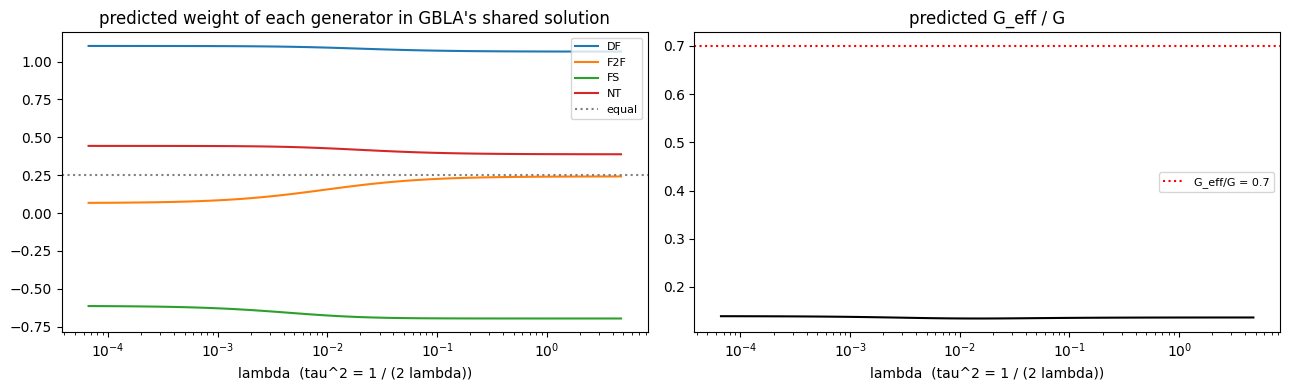

curvature eigenvalues in the subspace range from 0.00664 to 0.0475


In [15]:
# 5.4 What GBLA would do: weights and G_eff as a function of lambda
def psd(A):
    vals, vecs = np.linalg.eigh(A)
    return (vecs * np.clip(vals, 0, None)) @ vecs.T


H_psd = {g: psd(H_star_s[g]) for g in TRAIN_GENERATORS}
eigs = np.concatenate([np.linalg.eigvalsh(H) for H in H_psd.values()])
pos = eigs[eigs > 1e-12]
lams = np.logspace(np.log10(pos.min()) - 2, np.log10(pos.max()) + 2, 80)
curve = []
for lam in lams:
    A = {g: np.linalg.solve(H_psd[g] + 2 * lam * np.eye(G), H_psd[g]) for g in TRAIN_GENERATORS}
    c_s = np.linalg.solve(sum(A.values()), sum(A[g] @ C[:, k] for k, g in enumerate(TRAIN_GENERATORS)))
    w = norm(np.linalg.solve(C, c_s))
    curve.append({"lambda": lam, "tau2": 1 / (2 * lam), "G_eff": g_eff(w), **{SHORT[g]: w[k] for k, g in enumerate(TRAIN_GENERATORS)}})
curve = pd.DataFrame(curve)
curve.to_csv(M3_DIR / "e1_lambda_curve.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for g in TRAIN_GENERATORS:
    axes[0].plot(curve["lambda"], curve[SHORT[g]], label=SHORT[g])
axes[0].axhline(1 / G, color="gray", linestyle=":", label="equal")
axes[0].set_title("predicted weight of each generator in GBLA's shared solution")
axes[1].plot(curve["lambda"], curve["G_eff"] / G, color="black")
axes[1].axhline(GO_MAX_GEFF_RATIO, color="red", linestyle=":", label=f"G_eff/G = {GO_MAX_GEFF_RATIO}")
axes[1].set_title("predicted G_eff / G")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("lambda  (tau^2 = 1 / (2 lambda))")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

balanced = curve[curve["G_eff"] >= 0.95 * G]
if len(balanced):
    print(f"G_eff >= 0.95 G for lambda <= {balanced['lambda'].max():.3g}  (tau^2 >= {balanced['tau2'].min():.3g})")
print(f"curvature eigenvalues in the subspace range from {pos.min():.3g} to {pos.max():.3g}")

### 5.5 Verdict

GO for GBLA (M4) if both hold:

1. **The curvature model explains pooled training:** geometric and curvature-predicted weights rank the generators the same way and differ by at most 0.10 (normalised).
2. **There is a real imbalance:** G_eff / G ≤ 0.70 for the geometric weights.

The verdict is a guide for the decision, not a proof: read it together with the checks in 5.3 (a small explained share or large ε disagreement weakens it). Saved with all numbers to `runs/m3/e1_summary.json`.

In [16]:
# 5.5 Verdict
wg, wc = norm(w_geo), norm(w_curv)
same_ranking = list(np.argsort(-wg)) == list(np.argsort(-wc))
max_diff = float(np.abs(wg - wc).max())
geff_ratio = g_eff(wg) / G
agree = same_ranking and max_diff <= GO_MAX_WEIGHT_DIFF
imbalance = geff_ratio <= GO_MAX_GEFF_RATIO

verdict = pd.Series({
    "same ranking (geometric vs curvature)": same_ranking,
    "max |weight difference|": round(max_diff, 3),
    f"agree (<= {GO_MAX_WEIGHT_DIFF})": agree,
    "G_eff / G (geometric)": round(geff_ratio, 3),
    f"imbalance (<= {GO_MAX_GEFF_RATIO})": imbalance,
    "share of theta* - theta0 inside the span": round(explained, 3),
    "VERDICT": "GO" if agree and imbalance else "NO-GO",
}, name="value")
display(verdict.to_frame())
if not agree:
    print("-> the curvature model does not explain where pooled training went")
if not imbalance:
    print("-> pooled training already weights the generators nearly equally")

(M3_DIR / "e1_summary.json").write_text(json.dumps({
    "generators": [SHORT[g] for g in TRAIN_GENERATORS],
    "weights": {k: [float(v) for v in col] for k, col in weights.items()},
    "explained_share": explained, "prediction_error": pred_err,
    "g_eff_geometric": g_eff(wg), "g_eff_curvature": g_eff(wc),
    "same_ranking": same_ranking, "max_weight_diff": max_diff,
    "checks": checks.astype(float).round(6).to_dict(),
    "cross_generator_video_auc": cross.round(2).to_dict(),
    "verdict": verdict["VERDICT"],
}, indent=1))

,value
same ranking (geometric vs curvature),False
max |weight difference|,0.315
agree (<= 0.1),False
G_eff / G (geometric),0.569
imbalance (<= 0.7),True
share of theta* - theta0 inside the span,0.645
VERDICT,NO-GO


-> the curvature model does not explain where pooled training went


2496